# Feature Scaling

1. Standarization
2. normalization

# Standarization (Z-score normalization)

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [14]:
df= pd.read_csv("Social_Network_Ads.csv")

In [15]:
df.sample(5)

,Age,EstimatedSalary,Purchased
74,32,18000,0
27,47,30000,1
291,49,89000,1
23,45,22000,1
237,37,80000,0


# Train_Test split 

In [16]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    df.drop("Purchased",axis=1),
    df["Purchased"],
    test_size=0.3,
    random_state=0
)

X_train.shape, X_test.shape

((280, 2), (120, 2))

# StandardScaler

In [17]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()

# Fit the Scaler to the trainset, it will learn the parammeters 
scaler.fit(X_train)

#Transform train and test set 
X_train_scaled= scaler.transform(X_train)
X_test_scaled= scaler.transform(X_test)

In [18]:
X_train

,Age,EstimatedSalary
92,26,15000
223,60,102000
234,38,112000
232,40,107000
377,42,53000
...,...,...
323,48,30000
192,29,43000
117,36,52000
47,27,54000


In [19]:
scaler.mean_

array([3.78642857e+01, 6.98071429e+04])

In [20]:
X_train_scaled

array([[-1.1631724 , -1.5849703 ],
       [ 2.17018137,  0.93098672],
       [ 0.0133054 ,  1.22017719],
       [ 0.20938504,  1.07558195],
       [ 0.40546467, -0.48604654],
       [-0.28081405, -0.31253226],
       [ 0.99370357, -0.8330751 ],
       [ 0.99370357,  1.8563962 ],
       [ 0.0133054 ,  1.24909623],
       [-0.86905295,  2.26126285],
       [-1.1631724 , -1.5849703 ],
       [ 2.17018137, -0.80415605],
       [-1.35925203, -1.46929411],
       [ 0.40546467,  2.2901819 ],
       [ 0.79762394,  0.75747245],
       [-0.96709276, -0.31253226],
       [ 0.11134522,  0.75747245],
       [-0.96709276,  0.55503912],
       [ 0.30742485,  0.06341534],
       [ 0.69958412, -1.26686079],
       [-0.47689368, -0.0233418 ],
       [-1.7514113 ,  0.3526058 ],
       [-0.67297331,  0.12125343],
       [ 0.40546467,  0.29476771],
       [-0.28081405,  0.06341534],
       [-0.47689368,  2.2901819 ],
       [ 0.20938504,  0.03449629],
       [ 1.28782302,  2.20342476],
       [ 0.79762394,

In [21]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [22]:
#The standard scaler takes the dataframe but returns the numpy array.

In [23]:
np.round(X_train.describe(),1)

,Age,EstimatedSalary
count,280.0,280.0
mean,37.9,69807.1
std,10.2,34641.2
min,18.0,15000.0
25%,30.0,43000.0
50%,37.0,70500.0
75%,46.0,88000.0
max,60.0,150000.0


In [25]:
np.round(X_train_scaled.describe(),1)

,Age,EstimatedSalary
count,280.0,280.0
mean,0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.8,-0.8
50%,-0.1,0.0
75%,0.8,0.5
max,2.2,2.3


# Effect of Scaling

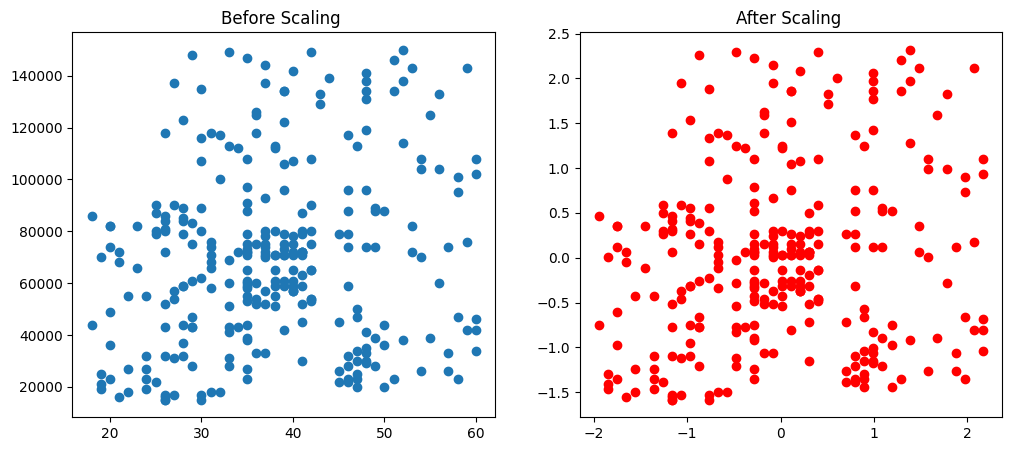

In [29]:
fig, (ax1, ax2)= plt.subplots(ncols=2, figsize=(12,5))

ax1.scatter(X_train['Age'],X_train['EstimatedSalary'])
ax1.set_title("Before Scaling ")

ax2.scatter(X_train_scaled['Age'],X_train_scaled['EstimatedSalary'],color="red")
ax2.set_title("After Scaling ")

plt.show()

- Basically, the shape and the distribution of the data will not be changed . The scaled is reduced and is limitted within the SD of 1 .
- The data is just centered .

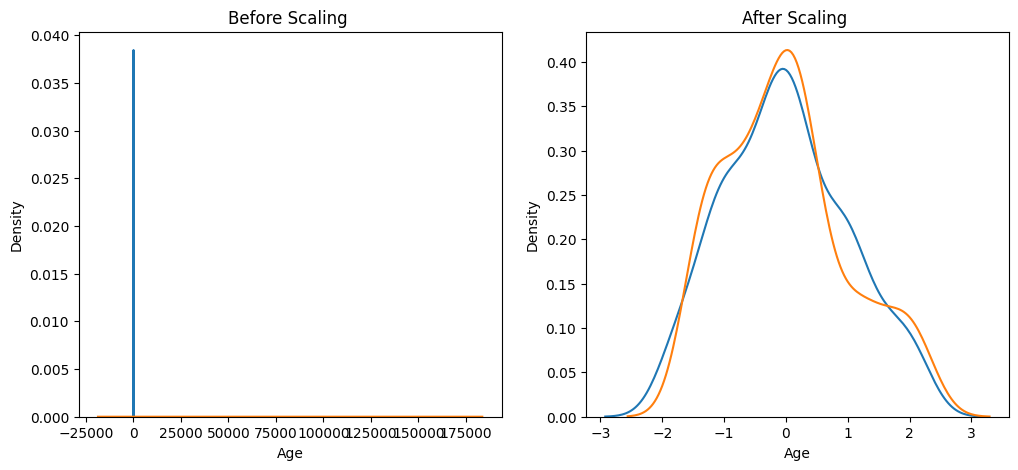

In [31]:
fig, (ax1, ax2)= plt.subplots(ncols=2, figsize=(12,5))

#Before Scaling 
ax1.set_title("Before Scaling ")
sns.kdeplot(X_train["Age"],ax=ax1)
sns.kdeplot(X_train["EstimatedSalary"],ax=ax1)

#After Scaling
ax2.set_title("After Scaling ")
sns.kdeplot(X_train_scaled["Age"],ax=ax2)
sns.kdeplot(X_train_scaled["EstimatedSalary"],ax=ax2)

plt.show()

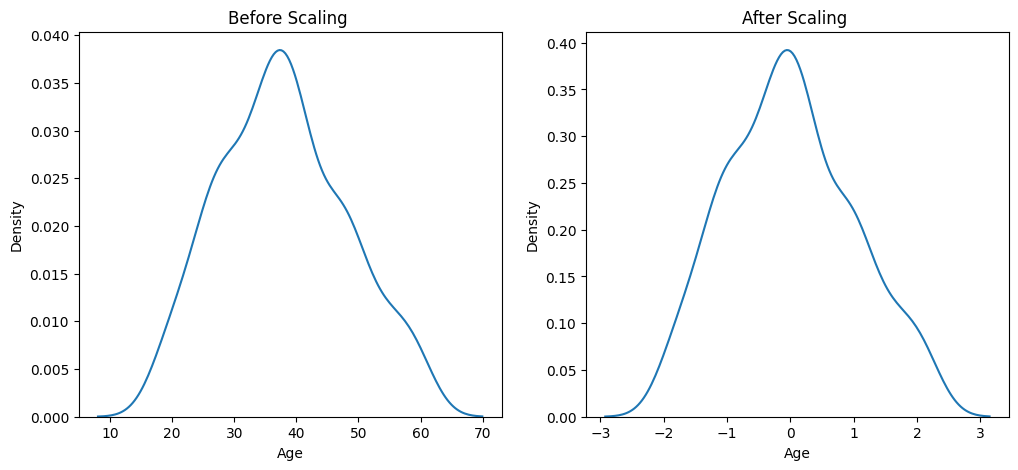

In [32]:
fig, (ax1, ax2)= plt.subplots(ncols=2, figsize=(12,5))

#Before Scaling 
ax1.set_title("Before Scaling ")
sns.kdeplot(X_train["Age"],ax=ax1)


#After Scaling
ax2.set_title("After Scaling ")
sns.kdeplot(X_train_scaled["Age"],ax=ax2)


plt.show()

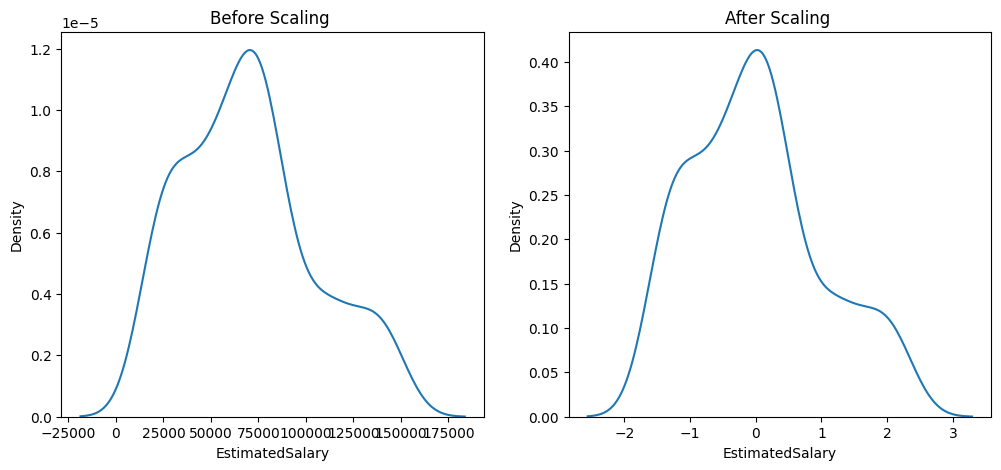

In [33]:
fig, (ax1, ax2)= plt.subplots(ncols=2, figsize=(12,5))

#Before Scaling 
ax1.set_title("Before Scaling ")
# sns.kdeplot(X_train["Age"],ax=ax1)
sns.kdeplot(X_train["EstimatedSalary"],ax=ax1)

#After Scaling
ax2.set_title("After Scaling ")
# sns.kdeplot(X_train_scaled["Age"],ax=ax2)
sns.kdeplot(X_train_scaled["EstimatedSalary"],ax=ax2)

plt.show()

# Why is scaling important ?

In [34]:
from sklearn.linear_model import LogisticRegression

In [35]:
lr= LogisticRegression()
lr_scaled= LogisticRegression()

In [37]:
lr.fit(X_train, y_train)
lr_scaled.fit(X_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [38]:
y_pred= lr.predict(X_test)
y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [39]:
from sklearn.metrics import accuracy_score

In [40]:
print("Actual",accuracy_score(y_test,y_pred))
print("Scaled",accuracy_score(y_test,y_pred_scaled))

Actual 0.875
Scaled 0.8666666666666667


# When to use standarization?
- K means
- K_nearest neighbours
- Principal Component Analysis
- Artificial Neural Network
- Gradient Descent 

- Even there is an outlier , after standarization also , it will be outlier .

# When NOT?
- Decision Tree
- Random Forest
- Gradient Boost
- Xg boost 